# Boston Airbnb Pricing: Predictive Analytics for Hosts

**Goal.** Recommend a nightly price for a Boston Airbnb listing, based on what comparable listings charge today.

**Approach.**
1. Decide which data is needed and which columns are useful, leaky or empty.
2. Clean the data and explore it.
3. Engineer features a host can actually provide.
4. Train and compare several predictive-analytics methods:
   * **Baseline**: median price for the same neighbourhood and room type
   * **Linear Regression** (ordinary least squares)
   * **Lasso Regression** (L1-regularised linear model)
   * **Random Forest** (bagged decision trees)
   * **Gradient Boosting** (boosted decision trees)
5. Evaluate the models with cross-validation and a held-out test set, and pick the best one for pricing.
6. Export the models so the portfolio interface (`interface/index.html`) can price a listing in the browser.

**Source:** Inside Airbnb snapshot of Boston (`listings.csv`, `neighbourhoods.csv`, `neighbourhoods.geojson`).

In [1]:
import json, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, LassoCV, lasso_path
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path("../data")
OUT = Path("../interface")
SEED = 42

## 1. What data do we need?

Three files are provided:

| File | Content | Use |
|---|---|---|
| `listings.csv` | One row per active listing (4,368 rows, 19 columns) | **Main modelling table.** `price` is the target. |
| `neighbourhoods.csv` | The 25 official Boston neighbourhoods | Lookup and validation of the `neighbourhood` category |
| `neighbourhoods.geojson` | Neighbourhood boundary polygons | Maps, and the clickable location picker in the interface |

The table below lists each column in `listings.csv` and whether the model uses it.

In [2]:
listings = pd.read_csv(DATA / "listings.csv")
hoods = pd.read_csv(DATA / "neighbourhoods.csv")
geo = json.loads((DATA / "neighbourhoods.geojson").read_text())

decision = {
    "id": ("Drop", "Identifier only"),
    "name": ("Feature source", "Title text -> bedrooms, studio, amenity keywords"),
    "host_id": ("Drop", "Identifier; would let the model memorise hosts"),
    "host_profile_id": ("Drop", "Identifier"),
    "host_name": ("Drop", "Personal data, no pricing signal"),
    "neighbourhood_group": ("Drop", "100% empty for Boston"),
    "neighbourhood": ("Feature", "Location category (one-hot)"),
    "latitude": ("Feature", "Fine-grained location; also distance to downtown"),
    "longitude": ("Feature", "Fine-grained location"),
    "room_type": ("Feature", "Entire home / private / hotel / shared"),
    "price": ("TARGET", "Nightly price in USD (log-transformed)"),
    "minimum_nights": ("Feature", "Short-stay vs monthly-rental strategy"),
    "number_of_reviews": ("Feature", "Track record / popularity"),
    "last_review": ("Drop", "Mostly duplicated by reviews_per_month; date"),
    "reviews_per_month": ("Feature", "Demand proxy (NaN -> 0)"),
    "calculated_host_listings_count": ("Feature", "Professional vs casual host"),
    "availability_365": ("Feature", "How many days the host opens the calendar"),
    "number_of_reviews_ltm": ("Feature", "Recent demand (last 12 months)"),
    "license": ("Feature source", "Licensed / exempt / none flags"),
}
inventory = pd.DataFrame({
    "dtype": listings.dtypes.astype(str),
    "missing_%": (listings.isna().mean() * 100).round(1),
    "example": listings.iloc[1],
})
inventory["decision"] = [decision[c][0] for c in inventory.index]
inventory["reason"] = [decision[c][1] for c in inventory.index]
print(listings.shape, "| official neighbourhoods:", len(hoods), "| polygons:", len(geo["features"]))
inventory

(4368, 19) | official neighbourhoods: 26 | polygons: 26


,dtype,missing_%,example,decision,reason
id,int64,0.0,5506,Drop,Identifier only
name,str,0.0,** Fort Hill Inn Private! Minutes to center!**,Feature source,"Title text -> bedrooms, studio, amenity keywords"
host_id,int64,0.0,8229,Drop,Identifier; would let the model memorise hosts
host_profile_id,int64,0.0,1462506610204730632,Drop,Identifier
host_name,str,0.0,Terry,Drop,"Personal data, no pricing signal"
neighbourhood_group,float64,100.0,NaN,Drop,100% empty for Boston
neighbourhood,str,0.0,Roxbury,Feature,Location category (one-hot)
latitude,float64,0.0,42.32844,Feature,Fine-grained location; also distance to downtown
longitude,float64,0.0,-71.09581,Feature,Fine-grained location
room_type,str,0.0,Entire home/apt,Feature,Entire home / private / hotel / shared


**Data we would add next, if available.** The detailed Inside Airbnb `listings.csv.gz` has bedrooms, bathrooms, accommodates, amenities and review scores, and `calendar.csv` has occupancy and seasonality. They would improve accuracy a lot. This summary file has none of them, so we pull the strongest of those signals (bedroom count, studio, amenities) out of the listing **title**.

## 2. Cleaning

In [3]:
df = listings.copy()
n0 = len(df)
df = df[df["price"].notna()]                    # 882 listings have no price (inactive / unavailable)
n1 = len(df)
upper = 2000                                    # ~top 1%: mansions, event pricing, data errors
df = df[df["price"].between(30, upper)]
n2 = len(df)
assert set(df["neighbourhood"]) <= set(hoods["neighbourhood"]), "unknown neighbourhood"
print(f"rows: {n0} -> {n1} after dropping missing price -> {n2} after removing price > ${upper}")
df["price"].describe(percentiles=[.05, .25, .5, .75, .95]).round(1)

rows: 4368 -> 3486 after dropping missing price -> 3480 after removing price > $2000


count    3480.0
mean      309.6
std       241.1
min        30.0
5%         64.0
25%       150.0
50%       253.0
75%       396.0
95%       758.0
max      1943.0
Name: price, dtype: float64

## 3. Exploratory analysis

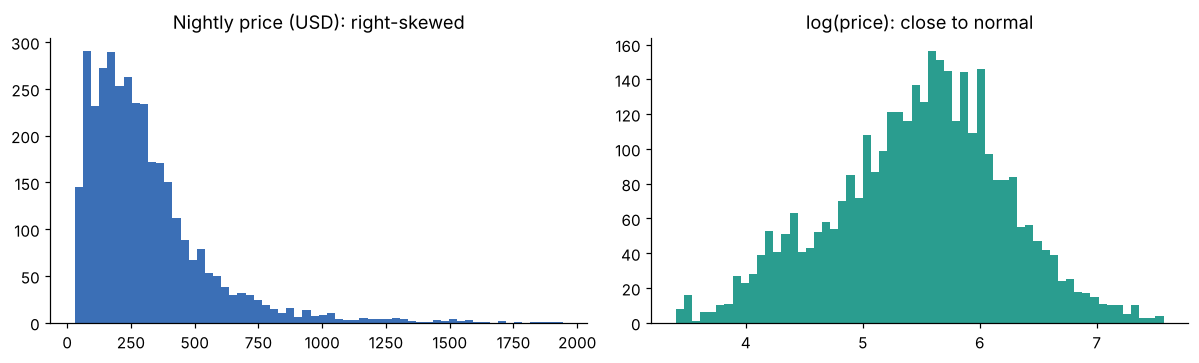

We model log(price): errors become relative (%), and linear models fit much better.


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(df["price"], bins=60, color="#3b6fb6"); ax[0].set_title("Nightly price (USD): right-skewed")
ax[1].hist(np.log(df["price"]), bins=60, color="#2a9d8f"); ax[1].set_title("log(price): close to normal")
plt.tight_layout(); plt.show()
print("We model log(price): errors become relative (%), and linear models fit much better.")

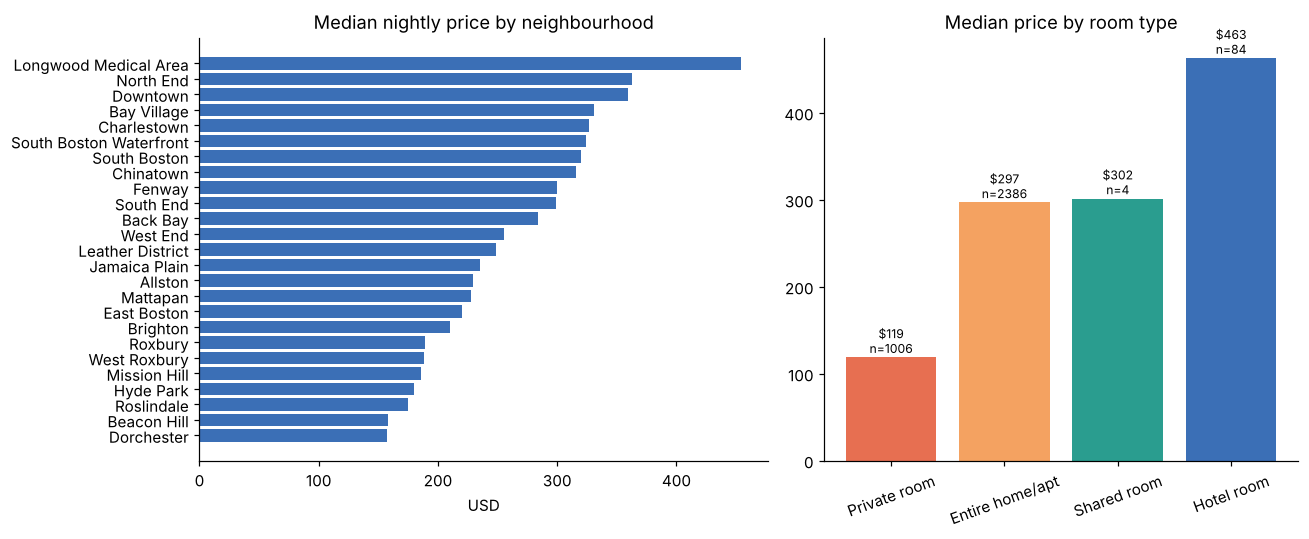

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.2, 1]})
by_hood = df.groupby("neighbourhood")["price"].agg(["median", "count"]).sort_values("median")
ax[0].barh(by_hood.index, by_hood["median"], color="#3b6fb6")
ax[0].set_title("Median nightly price by neighbourhood"); ax[0].set_xlabel("USD")
rt = df.groupby("room_type")["price"].agg(["median", "count"]).sort_values("median")
ax[1].bar(rt.index, rt["median"], color=["#e76f51", "#f4a261", "#2a9d8f", "#3b6fb6"])
ax[1].set_title("Median price by room type"); ax[1].tick_params(axis="x", rotation=20)
for i, (m, c) in enumerate(zip(rt["median"], rt["count"])):
    ax[1].text(i, m + 5, f"${m:.0f}\nn={c}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

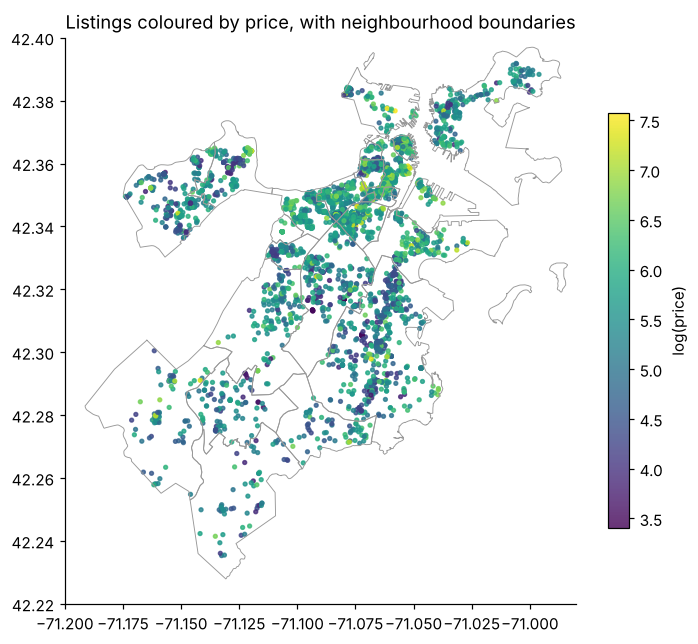

In [6]:
def draw_boundaries(ax):
    for f in geo["features"]:
        for poly in f["geometry"]["coordinates"]:
            ring = np.array(poly[0])
            ax.plot(ring[:, 0], ring[:, 1], color="#999", lw=0.6)

fig, ax = plt.subplots(figsize=(7.5, 7))
draw_boundaries(ax)
sc = ax.scatter(df["longitude"], df["latitude"], c=np.log(df["price"]), s=6, cmap="viridis", alpha=.8)
cb = plt.colorbar(sc, ax=ax, shrink=.7); cb.set_label("log(price)")
ax.set_title("Listings coloured by price, with neighbourhood boundaries")
ax.set_aspect(1 / np.cos(np.radians(42.33))); ax.set_xlim(-71.2, -70.98); ax.set_ylim(42.22, 42.40)
plt.show()

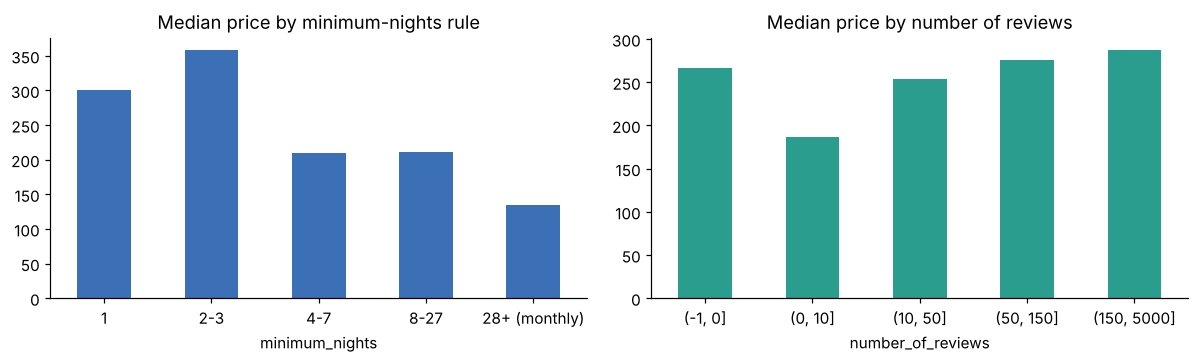

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
mn = df["minimum_nights"].fillna(1)
grp = pd.cut(mn, [0, 1, 3, 7, 27, 10000], labels=["1", "2-3", "4-7", "8-27", "28+ (monthly)"])
df.groupby(grp, observed=True)["price"].median().plot.bar(ax=ax[0], color="#3b6fb6", rot=0)
ax[0].set_title("Median price by minimum-nights rule")
df.groupby(pd.cut(df["number_of_reviews"], [-1, 0, 10, 50, 150, 5000]), observed=True)["price"].median().plot.bar(ax=ax[1], color="#2a9d8f", rot=0)
ax[1].set_title("Median price by number of reviews")
plt.tight_layout(); plt.show()

**What the exploration shows**
* **Room type** is the biggest driver: an entire home costs roughly 2-3x a private room.
* **Location matters**: Back Bay, the Waterfront, Downtown and Beacon Hill sit well above Dorchester, Mattapan and Hyde Park.
* **Short-stay listings (1-3 night minimum) charge more per night** than 28+ night monthly rentals, which are priced as discounted month-long stays.
* Listings with **no reviews** have a wider price spread, because many of them are new or not actively managed.

## 4. Feature engineering

Every feature is something a host knows about their own listing, so the interface can ask for it:

| Feature | Built from |
|---|---|
| `bedrooms`, `bedrooms_known` | Regex on title ("3BR", "2 bedroom", "Studio" = 0). Missing values set to 1 and flagged |
| `private_room`, `hotel_room`, `shared_room` | One-hot `room_type` (entire home = reference) |
| `log_min_nights`, `monthly` | log(1+minimum_nights); flag for 28+ nights |
| `log_reviews`, `reviews_per_month`, `number_of_reviews_ltm` | Track record and demand |
| `log_host_listings` | log(1 + host's listing count): professional operator signal |
| `availability_365` | Calendar openness |
| `licensed`, `exempt` | From `license` text |
| `dist_km` | Distance to Boston Common (42.3550, -71.0656) |
| `latitude`, `longitude` | Raw coordinates (useful for tree models) |
| `kw_*` | Title mentions parking / luxury-modern / view-rooftop / gym-pool-concierge / managed-furnished brand |
| `nb_*` | One-hot neighbourhood (25) |

In [8]:
CENTER = (42.3550, -71.0656)
KEYWORDS = {
    "kw_parking":   r"parking|garage",
    "kw_luxury":    r"luxur|modern|renovat|designer|stylish|chic|upscale|elegant",
    "kw_view":      r"view|rooftop|roof deck|skyline|waterfront|harbor",
    "kw_amenities": r"gym|pool|fitness|concierge|doorman",
    "kw_managed":   r"blueground|sonder|landing|kasa|furnished|corporate",
}
NEIGHBOURHOODS = sorted(hoods["neighbourhood"])

def extract_bedrooms(title: str):
    t = title.lower()
    if "studio" in t:
        return 0
    m = re.search(r"(\d+)\s*-?\s*(?:br\b|bd\b|bdr|bed|bedroom|b/r)", t)
    return min(int(m.group(1)), 8) if m else np.nan

def build_features(d: pd.DataFrame) -> pd.DataFrame:
    title = d["name"].fillna("").str.lower()
    beds = d["name"].fillna("").map(extract_bedrooms)
    lic = d["license"].fillna("").str.lower()
    mn = d["minimum_nights"].fillna(1)
    X = pd.DataFrame(index=d.index)
    X["bedrooms"] = beds.fillna(1)
    X["bedrooms_known"] = beds.notna().astype(int)
    X["private_room"] = (d["room_type"] == "Private room").astype(int)
    X["hotel_room"] = (d["room_type"] == "Hotel room").astype(int)
    X["shared_room"] = (d["room_type"] == "Shared room").astype(int)
    X["log_min_nights"] = np.log1p(mn)
    X["monthly"] = (mn >= 28).astype(int)
    X["log_reviews"] = np.log1p(d["number_of_reviews"])
    X["reviews_per_month"] = d["reviews_per_month"].fillna(0)
    X["number_of_reviews_ltm"] = d["number_of_reviews_ltm"]
    X["log_host_listings"] = np.log1p(d["calculated_host_listings_count"])
    X["availability_365"] = d["availability_365"]
    X["licensed"] = lic.str.startswith("str").astype(int)
    X["exempt"] = lic.str.contains("exempt").astype(int)
    X["dist_km"] = np.sqrt(((d["latitude"] - CENTER[0]) * 111.0) ** 2 + ((d["longitude"] - CENTER[1]) * 82.0) ** 2)
    X["latitude"] = d["latitude"]
    X["longitude"] = d["longitude"]
    for k, pat in KEYWORDS.items():
        X[k] = title.str.contains(pat).astype(int)
    for h in NEIGHBOURHOODS:
        X["nb_" + h] = (d["neighbourhood"] == h).astype(int)
    return X.astype(float)

X = build_features(df)
y = np.log(df["price"])
FEATURES = list(X.columns)
print(X.shape)
print(f"bedrooms parsed from title for {X['bedrooms_known'].mean():.0%} of listings")
X.describe().T.iloc[:22, [1, 2, 3, 7]].round(2)

(3480, 48)
bedrooms parsed from title for 39% of listings


,mean,std,min,max
bedrooms,1.21,0.94,0.00,8.00
bedrooms_known,0.39,0.49,0.00,1.00
private_room,0.29,0.45,0.00,1.00
hotel_room,0.02,0.15,0.00,1.00
shared_room,0.00,0.03,0.00,1.00
log_min_nights,1.74,1.34,0.69,5.60
monthly,0.32,0.47,0.00,1.00
log_reviews,2.96,1.84,0.00,6.94
reviews_per_month,1.77,2.08,0.00,28.30
number_of_reviews_ltm,15.18,21.05,0.00,314.00


## 5. Experimental set-up

* **80/20 train-test split** (random, seed 42). The test set is used **once**, at the end.
* **5-fold cross-validation** on the training set for tuning and model comparison.
* Models predict **log(price)**; we convert back with `exp()` and report errors in **dollars**:
  * **MAE**: average dollars off per night (the easiest number for a host to understand)
  * **RMSE**: like MAE but penalises big misses more
  * **R² (log)**: share of price variation explained
  * **MAPE / within 20%**: relative accuracy (how often the suggestion is within ±20% of the actual price)

In [9]:
X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(
    X, y, df, test_size=0.2, random_state=SEED)
cv = KFold(5, shuffle=True, random_state=SEED)
print("train", X_train.shape, "test", X_test.shape)

def evaluate(name, y_true_log, y_pred_log):
    t, p = np.exp(y_true_log), np.exp(y_pred_log)
    return {
        "model": name,
        "MAE_$": mean_absolute_error(t, p),
        "RMSE_$": mean_squared_error(t, p) ** 0.5,
        "R2_log": r2_score(y_true_log, y_pred_log),
        "MAPE_%": np.mean(np.abs(p - t) / t) * 100,
        "within_20%": np.mean(np.abs(p - t) / t <= 0.2) * 100,
    }

train (2784, 48) test (696, 48)


## 6. Models

### 6.0 Baseline: neighbourhood × room-type median
The rule of thumb many hosts use: copy the median price of similar listings nearby. A model is only worth using if it beats this.

In [10]:
class GroupMedian(BaseEstimator, RegressorMixin):
    # Predict the median log-price of the (neighbourhood, room type) cell; fall back to room-type median.
    def _keys(self, X):
        hood = X[[c for c in X.columns if c.startswith("nb_")]].idxmax(axis=1)
        room = np.select([X["private_room"] == 1, X["hotel_room"] == 1, X["shared_room"] == 1],
                         ["private", "hotel", "shared"], "entire")
        return hood.values, room
    def fit(self, X, y):
        h, r = self._keys(X); t = pd.DataFrame({"h": h, "r": r, "y": np.asarray(y)})
        self.cell_ = t.groupby(["h", "r"])["y"].median().to_dict()
        self.room_ = t.groupby("r")["y"].median().to_dict(); self.all_ = t["y"].median()
        return self
    def predict(self, X):
        h, r = self._keys(X)
        return np.array([self.cell_.get((a, b), self.room_.get(b, self.all_)) for a, b in zip(h, r)])

results, cv_scores, fitted, fit_time = [], {}, {}, {}

def run(name, model):
    t0 = time.time()
    scores = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    model.fit(X_train, y_train)
    fit_time[name] = time.time() - t0
    cv_scores[name] = scores; fitted[name] = model
    r = evaluate(name, y_test, model.predict(X_test)); r["CV_RMSE_log"] = scores.mean(); r["CV_std"] = scores.std()
    results.append(r)
    print(f"{name:18s} CV RMSE(log) = {scores.mean():.3f} ± {scores.std():.3f} | test MAE = ${r['MAE_$']:.0f}")
    return model

run("Baseline", GroupMedian())

Baseline           CV RMSE(log) = 0.593 ± 0.020 | test MAE = $128


Name,Type,Value
all_,float64,5.541
cell_,dict,"{('nb...on', 'entire'): 5.641907070938114, ('nb...on', 'private'): 4.442651256490317, ('nb...ay', 'entire'): 5.613101466006574, ('nb...ay', 'hotel'): 6.150602768446279, ...}"
room_,dict,"{'entire': 5.700443573390687, 'hotel': 6.1224928095143865, 'private': 4.804021044733257, 'shared': 6.246377108824186}"


### 6.1 Linear Regression (OLS)
Assumes log(price) is a **weighted sum** of the features. Each coefficient reads as "+x% price per unit". The model is transparent and fast, but it can't capture interactions such as "a monthly minimum stay matters more for entire homes".

In [11]:
ols = run("Linear Regression", Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]))

Linear Regression  CV RMSE(log) = 0.433 ± 0.016 | test MAE = $104


### 6.2 Lasso Regression (L1 regularisation)
Lasso is the same linear model with a penalty `α·Σ|β|` that **shrinks weak coefficients to exactly zero**, so it selects features automatically. `LassoCV` picks α by cross-validation.

In [12]:
lasso = run("Lasso", Pipeline([("scale", StandardScaler()),
                               ("model", LassoCV(alphas=np.logspace(-4, 0, 60), cv=cv, max_iter=50000))]))
alpha = lasso.named_steps["model"].alpha_
coef = pd.Series(lasso.named_steps["model"].coef_, FEATURES)
print(f"chosen alpha = {alpha:.5f}; features set to zero: {(coef == 0).sum()} of {len(coef)}")
print("zeroed:", list(coef[coef == 0].index))

Lasso              CV RMSE(log) = 0.433 ± 0.016 | test MAE = $104
chosen alpha = 0.00104; features set to zero: 4 of 48
zeroed: ['nb_Beacon Hill', 'nb_Brighton', 'nb_Harbor Islands', 'nb_West End']


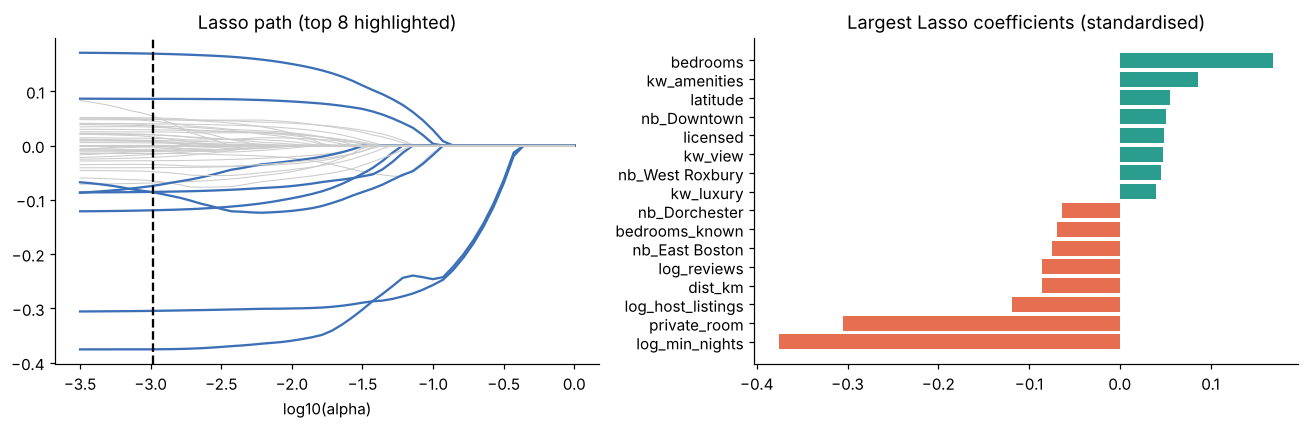

In [13]:
# Regularisation path: how coefficients shrink as alpha grows
Xs = lasso.named_steps["scale"].transform(X_train)
alphas, coefs, _ = lasso_path(Xs, y_train, alphas=np.logspace(-3.5, 0, 50))
top = np.argsort(-np.abs(coef.values))[:8]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i in range(coefs.shape[0]):
    ax[0].plot(np.log10(alphas), coefs[i], color="#3b6fb6" if i in top else "#ccc", lw=1.5 if i in top else .7)
ax[0].axvline(np.log10(alpha), ls="--", color="k"); ax[0].set_xlabel("log10(alpha)"); ax[0].set_title("Lasso path (top 8 highlighted)")
c = coef[coef != 0].sort_values(); c = pd.concat([c.head(8), c.tail(8)])
ax[1].barh(c.index, c.values, color=np.where(c > 0, "#2a9d8f", "#e76f51"))
ax[1].set_title("Largest Lasso coefficients (standardised)")
plt.tight_layout(); plt.show()

### 6.3 Random Forest
Hundreds of decision trees, each grown on a bootstrap sample with a random subset of features; the forest averages their predictions. It captures **non-linear effects and interactions** without needing scaling. We tune depth, leaf size and feature fraction with grid-search CV. The tree size is capped so the forest can be shipped to the browser.

In [14]:
rf_grid = GridSearchCV(
    RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1),
    {"max_depth": [10, 14], "min_samples_leaf": [2, 4], "max_features": [0.33, 0.5]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("best RF params:", rf_grid.best_params_)
rf = run("Random Forest", RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1, **rf_grid.best_params_))

best RF params: {'max_depth': 14, 'max_features': 0.5, 'min_samples_leaf': 2}


Random Forest      CV RMSE(log) = 0.380 ± 0.015 | test MAE = $86


### 6.4 Gradient Boosting
Trees are built **sequentially**, and each small tree corrects the errors of the ones before it. It is often the most accurate method on tabular data, but it is more sensitive to hyper-parameters (learning rate × number of trees × depth).

In [15]:
gb_grid = GridSearchCV(
    GradientBoostingRegressor(subsample=0.8, random_state=SEED),
    {"n_estimators": [300, 600], "learning_rate": [0.03, 0.06], "max_depth": [3, 4]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
gb_grid.fit(X_train, y_train)
print("best GB params:", gb_grid.best_params_)
gb = run("Gradient Boosting", GradientBoostingRegressor(subsample=0.8, random_state=SEED, **gb_grid.best_params_))

best GB params: {'learning_rate': 0.06, 'max_depth': 4, 'n_estimators': 600}


Gradient Boosting  CV RMSE(log) = 0.381 ± 0.011 | test MAE = $88


## 7. Comparing the methods

In [16]:
res = pd.DataFrame(results).set_index("model")
res["train_time_s"] = pd.Series(fit_time)
res["interpretability"] = ["Very high", "High", "High (sparse)", "Medium", "Low-Medium"]
res[["CV_RMSE_log", "CV_std", "MAE_$", "RMSE_$", "R2_log", "MAPE_%", "within_20%", "train_time_s", "interpretability"]].round(3)

,CV_RMSE_log,CV_std,MAE_$,RMSE_$,R2_log,MAPE_%,within_20%,train_time_s,interpretability
model,,,,,,,,,
Baseline,0.593,0.020,128.223,205.978,0.397,49.919,30.460,0.066,Very high
Linear Regression,0.433,0.016,104.070,178.917,0.684,34.960,37.213,0.074,High
Lasso,0.433,0.016,104.102,179.030,0.684,35.001,38.362,0.352,High (sparse)
Random Forest,0.380,0.015,86.242,156.139,0.787,28.035,46.264,2.151,Medium
Gradient Boosting,0.381,0.011,87.813,152.515,0.784,28.878,44.397,19.605,Low-Medium


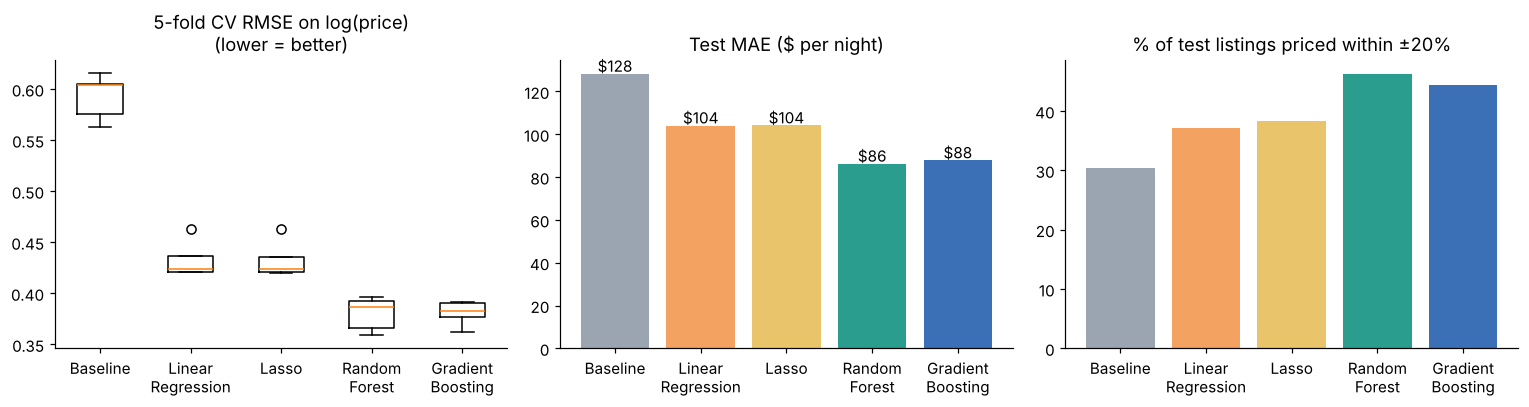

In [17]:
names = list(res.index)
colors = ["#9aa5b1", "#f4a261", "#e9c46a", "#2a9d8f", "#3b6fb6"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].boxplot([cv_scores[n] for n in names]); ax[0].set_xticks(range(1, len(names) + 1), [n.replace(" ", "\n") for n in names])
ax[0].set_title("5-fold CV RMSE on log(price)\n(lower = better)")
ax[1].bar(range(len(names)), res["MAE_$"], color=colors); ax[1].set_xticks(range(len(names)), [n.replace(" ", "\n") for n in names])
ax[1].set_title("Test MAE ($ per night)")
for i, v in enumerate(res["MAE_$"]): ax[1].text(i, v + 1, f"${v:.0f}", ha="center")
ax[2].bar(range(len(names)), res["within_20%"], color=colors); ax[2].set_xticks(range(len(names)), [n.replace(" ", "\n") for n in names])
ax[2].set_title("% of test listings priced within ±20%")
plt.tight_layout(); plt.show()

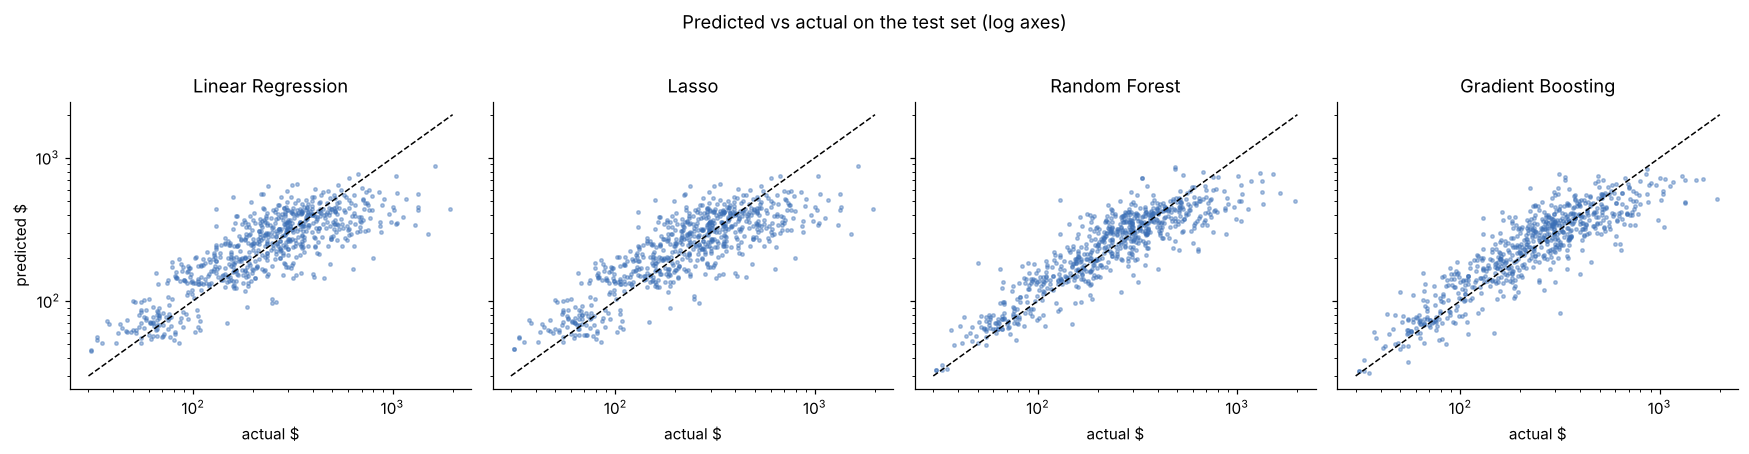

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, n in zip(axes, names[1:]):
    p = np.exp(fitted[n].predict(X_test)); t = np.exp(y_test)
    ax.scatter(t, p, s=5, alpha=.4, color="#3b6fb6"); ax.plot([30, 2000], [30, 2000], "k--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(n); ax.set_xlabel("actual $")
axes[0].set_ylabel("predicted $"); plt.suptitle("Predicted vs actual on the test set (log axes)", y=1.02)
plt.tight_layout(); plt.show()

### Why the methods behave differently

| | Linear Regression | Lasso | Random Forest | Gradient Boosting |
|---|---|---|---|---|
| **Shape of relationship** | Straight-line, additive | Straight-line, additive | Any shape, interactions | Any shape, interactions |
| **Feature selection** | None | Automatic (L1 → zeros) | Implicit (splits) | Implicit (splits) |
| **Overfitting control** | None | α penalty | Bagging + leaf size | Learning rate + depth + subsampling |
| **Explainability** | Coefficient = % effect | Same, fewer terms | Feature importance | Feature importance |
| **Data needs** | Low | Low | Medium | Medium |

* **Linear vs Lasso perform almost identically** here. There are only about 47 features against 2,700+ training rows, so overfitting is mild and the optimal α is small. Lasso's value is **simplicity**: it zeroes the weak features and keeps the same accuracy.
* **Tree ensembles win clearly.** Price depends on interactions: a monthly-minimum rule reduces price much more for entire homes in prime areas, and location effects are not linear in latitude/longitude. Linear models can't represent those without hand-made interaction terms.
* **Random Forest vs Gradient Boosting** are close. The forest is more stable across folds and needs less tuning, and its trees give a natural **price range** (spread of tree predictions).

In [19]:
best_name = res["CV_RMSE_log"].idxmin()
best = fitted[best_name]
print("Best model by cross-validated RMSE:", best_name)
print(res.loc[best_name, ["MAE_$", "R2_log", "MAPE_%", "within_20%"]].round(2).to_dict())
improvement = 1 - res.loc[best_name, "MAE_$"] / res.loc["Baseline", "MAE_$"]
print(f"MAE improvement over the 'copy the neighbourhood median' baseline: {improvement:.0%}")

Best model by cross-validated RMSE: Random Forest
{'MAE_$': 86.24, 'R2_log': 0.79, 'MAPE_%': 28.03, 'within_20%': 46.26}
MAE improvement over the 'copy the neighbourhood median' baseline: 33%


### What drives price? (permutation importance on the best model)
Permutation importance measures how much test error grows when a feature's values are shuffled. It is model-agnostic and more reliable than impurity-based importance.

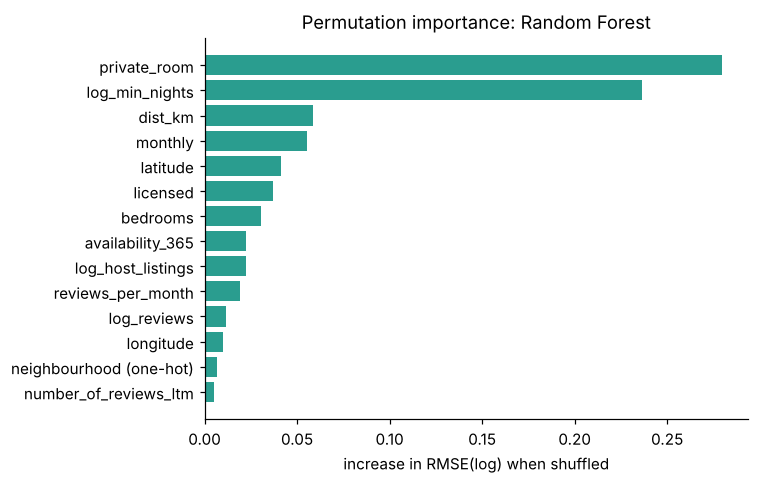

In [20]:
pi = permutation_importance(best, X_test, y_test, n_repeats=8, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, FEATURES)
# group the 26 neighbourhood dummies into one "neighbourhood" importance for readability
grouped = imp[[f for f in FEATURES if not f.startswith("nb_")]].copy()
grouped["neighbourhood (one-hot)"] = imp[[f for f in FEATURES if f.startswith("nb_")]].sum()
grouped = grouped.sort_values(ascending=True).tail(14)
plt.figure(figsize=(7, 4.5)); plt.barh(grouped.index, grouped.values, color="#2a9d8f")
plt.title(f"Permutation importance: {best_name}"); plt.xlabel("increase in RMSE(log) when shuffled"); plt.tight_layout(); plt.show()

In [21]:
# Lasso coefficients in plain language: % change in price, holding everything else fixed
raw = lasso.named_steps["model"].coef_ / lasso.named_steps["scale"].scale_
effects = pd.Series((np.exp(raw) - 1) * 100, FEATURES)
readable = effects[["private_room", "hotel_room", "shared_room", "monthly", "bedrooms", "kw_parking",
                    "kw_luxury", "kw_view", "licensed", "dist_km", "nb_Back Bay", "nb_Dorchester"]].round(1)
print("Lasso: % price effect of +1 unit of each feature")
readable.to_frame("% effect")

Lasso: % price effect of +1 unit of each feature


,% effect
private_room,-49.2
hotel_room,-12.5
shared_room,19.5
monthly,-3.1
bedrooms,19.6
kw_parking,-3.9
kw_luxury,11.6
kw_view,22.9
licensed,10.7
dist_km,-2.9


## 8. Which method should a host use?

**Recommendation: Random Forest (or Gradient Boosting) as the pricing engine, with Lasso as the explanation layer.**

* The tree ensembles have the **lowest cross-validated and test error**. They cut the dollar error substantially compared with the neighbourhood-median rule of thumb and with linear models.
* The Random Forest also gives a **range** (the spread of its 150 tree predictions), which is more useful to a host than one number.
* Lasso is less accurate, but its coefficients say *why*: "+x% for an entire home", "−y% for a monthly minimum stay". The interface shows both.

The cell below turns the chosen model into a pricing function for one listing.

In [22]:
# Residual quantiles on the test set -> an honest 80% price band around any prediction
resid = y_test - best.predict(X_test)
band = (float(np.quantile(resid, 0.10)), float(np.quantile(resid, 0.90)))

def price_listing(neighbourhood, room_type, bedrooms=1, minimum_nights=2, number_of_reviews=0,
                  reviews_per_month=0.0, number_of_reviews_ltm=0, host_listings=1, availability_365=180,
                  license="STR-000000", title="", lat=None, lon=None):
    sub = df[df["neighbourhood"] == neighbourhood]
    if sub.empty:                                   # e.g. Harbor Islands has no listings
        sub = df
    row = pd.DataFrame([{
        "name": title + (" studio" if bedrooms == 0 else f" {bedrooms}BR"),
        "neighbourhood": neighbourhood, "room_type": room_type,
        "latitude": lat if lat is not None else sub["latitude"].median(),
        "longitude": lon if lon is not None else sub["longitude"].median(),
        "minimum_nights": minimum_nights, "number_of_reviews": number_of_reviews,
        "reviews_per_month": reviews_per_month, "number_of_reviews_ltm": number_of_reviews_ltm,
        "calculated_host_listings_count": host_listings, "availability_365": availability_365,
        "license": license}])
    x = build_features(row)[FEATURES]
    out = {n: float(np.exp(m.predict(x))[0]) for n, m in fitted.items()}
    out["range_low"], out["range_high"] = np.exp(np.log(out[best_name]) + np.array(band))
    return {k: round(v) for k, v in out.items()}

example = price_listing("South End", "Entire home/apt", bedrooms=2, minimum_nights=2, number_of_reviews=25,
                        reviews_per_month=1.5, number_of_reviews_ltm=10, title="Modern 2BR with parking")
example

{'Baseline': 310,
 'Linear Regression': 551,
 'Lasso': 548,
 'Random Forest': 574,
 'Gradient Boosting': 749,
 'range_low': 373,
 'range_high': 858}

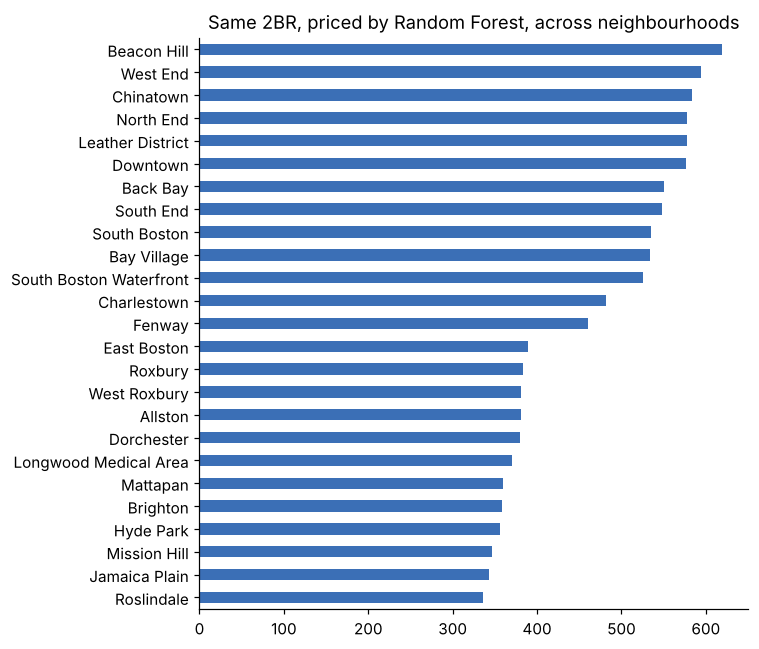

In [23]:
# Same listing priced in every neighbourhood: where does location add the most value?
comp = pd.Series({h: price_listing(h, "Entire home/apt", 2, 2, 25, 1.5, 10)[best_name] for h in df["neighbourhood"].unique()}).sort_values()
comp.plot.barh(figsize=(7, 6), color="#3b6fb6", title=f"Same 2BR, priced by {best_name}, across neighbourhoods"); plt.tight_layout(); plt.show()

## 9. Export for the portfolio interface
The cell below refits every model on **all** cleaned data (train + test) and serialises it to `interface/data.js`:
* Linear Regression and Lasso → intercept, coefficients and scaler mean/std
* Random Forest and Gradient Boosting → compact pre-order tree arrays (feature, threshold-or-value, right child)
* Baseline → median lookup table
* Plus the evaluation metrics, importances, neighbourhood stats and simplified boundaries for the charts and map.

The JavaScript in `interface/index.html` re-implements `build_features` and tree traversal, so the browser gives the same prediction as Python for the same input. `scripts/verify_js.js` checks this.

In [24]:
def export_tree(t, scale=1.0):
    # Compact pre-order encoding: the left child of node i is always i+1 (sklearn depth-first builder),
    # so we only store f (feature, -1 = leaf), x (threshold, or leaf value) and r (right-child index).
    tr = t.tree_
    leaf = tr.children_left == -1
    assert np.all(tr.children_left[~leaf] == np.arange(tr.node_count)[~leaf] + 1)
    # thresholds keep 9 significant digits (lat/lon splits need them); leaf values 6
    x = [float(f"{v * scale:.6g}") if is_leaf else float(f"{th:.9g}")
         for v, th, is_leaf in zip(tr.value[:, 0, 0], tr.threshold, leaf)]
    return {"f": np.where(leaf, -1, tr.feature).tolist(),
            "x": x,
            "r": np.where(leaf, 0, tr.children_right).tolist()}

def export_linear(pipe):
    m, s = pipe.named_steps["model"], pipe.named_steps["scale"]
    return {"intercept": float(m.intercept_), "coef": np.round(m.coef_, 6).tolist(),
            "mean": np.round(s.mean_, 6).tolist(), "scale": np.round(s.scale_, 6).tolist()}

# refit on all data with the tuned settings
final = {
    "Baseline": GroupMedian().fit(X, y),
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]).fit(X, y),
    "Lasso": Pipeline([("scale", StandardScaler()), ("model", LassoCV(alphas=[alpha], cv=cv))]).fit(X, y),
    "Random Forest": RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1, **rf_grid.best_params_).fit(X, y),
    "Gradient Boosting": GradientBoostingRegressor(subsample=0.8, random_state=SEED, **gb_grid.best_params_).fit(X, y),
}
gbf = final["Gradient Boosting"]
models_json = {
    "Baseline": {"cell": {f"{h}|{r}": round(v, 5) for (h, r), v in final["Baseline"].cell_.items()},
                 "room": {k: round(v, 5) for k, v in final["Baseline"].room_.items()}, "all": final["Baseline"].all_},
    "Linear Regression": export_linear(final["Linear Regression"]),
    "Lasso": export_linear(final["Lasso"]),
    "Random Forest": {"trees": [export_tree(e) for e in final["Random Forest"].estimators_]},
    "Gradient Boosting": {"init": float(gbf.init_.constant_[0][0]),
                          "trees": [export_tree(e[0], gbf.learning_rate) for e in gbf.estimators_]},
}

# reference predictions so the JS port can be verified
ref_idx = X.sample(200, random_state=1).index
reference = {"X": X.loc[ref_idx].values.tolist(),
             "pred": {n: np.round(m.predict(X.loc[ref_idx]), 5).tolist() for n, m in final.items()}}

In [25]:
def simplify(coords, step=3):
    return [[round(x, 4), round(y, 4)] for x, y in coords[::step]] + [[round(coords[-1][0], 4), round(coords[-1][1], 4)]]

geo_small = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "properties": {"name": f["properties"]["neighbourhood"]},
     "geometry": {"type": "MultiPolygon", "coordinates": [[simplify(poly[0])] for poly in f["geometry"]["coordinates"] if len(poly[0]) > 8]}}
    for f in geo["features"]]}

hood_stats = df.groupby("neighbourhood").agg(
    median=("price", "median"), q25=("price", lambda s: s.quantile(.25)), q75=("price", lambda s: s.quantile(.75)),
    count=("price", "size"), lat=("latitude", "median"), lon=("longitude", "median"),
    share_entire=("room_type", lambda s: (s == "Entire home/apt").mean())).round(4)
room_stats = df.groupby("room_type")["price"].agg(["median", "count"]).round(1)

test_scatter = {n: {"actual": np.round(np.exp(y_test), 0).tolist()[:400],
                    "pred": np.round(np.exp(fitted[n].predict(X_test)), 0).tolist()[:400]} for n in names}
hist_counts, hist_edges = np.histogram(np.log(df["price"]), bins=40)

bundle = {
    "meta": {"rows_raw": int(n0), "rows_priced": int(n1), "rows_model": int(n2), "price_cap": upper,
             "n_train": len(X_train), "n_test": len(X_test), "n_features": len(FEATURES),
             "best": best_name, "band_log": band, "alpha": float(alpha), "center": CENTER,
             "rf_params": rf_grid.best_params_, "gb_params": gb_grid.best_params_,
             "lasso_zeroed": list(coef[coef == 0].index),
             "bedrooms_known_share": float(X["bedrooms_known"].mean()),
             "baseline_improvement": float(improvement)},
    "features": FEATURES, "keywords": KEYWORDS, "neighbourhoods": NEIGHBOURHOODS,
    "metrics": res.drop(columns=["interpretability"]).round(4).reset_index().to_dict(orient="records"),
    "cv_scores": {n: np.round(v, 4).tolist() for n, v in cv_scores.items()},
    "importance": grouped.sort_values(ascending=False).round(5).to_dict(),
    "lasso_effects": effects.round(2).to_dict(),
    "hood_stats": hood_stats.reset_index().to_dict(orient="records"),
    "room_stats": room_stats.reset_index().to_dict(orient="records"),
    "price_hist": {"counts": hist_counts.tolist(), "edges": np.round(np.exp(hist_edges), 1).tolist()},
    "test_scatter": test_scatter,
    "geo": geo_small,
    "models": models_json,
    "reference": reference,
}
OUT.mkdir(exist_ok=True)
payload = json.dumps(bundle, separators=(",", ":"))
(OUT / "data.js").write_text("window.PRICING = " + payload + ";\n")
print(f"wrote {OUT / 'data.js'}  ({len(payload) / 1e6:.2f} MB)")

wrote ../interface/data.js  (3.53 MB)


## 10. Limitations & next steps
* **Advertised price ≠ booked price.** The model learns what hosts *ask*, not what guests *pay*. Adding calendar/occupancy data would let us optimise revenue, not just match the market.
* **Missing property attributes.** Bedrooms come from titles for only part of the listings; bathrooms, capacity, amenities and review scores from the detailed file would cut the error further.
* **No seasonality.** This is one snapshot. Boston prices peak around graduation, marathon and fall foliage; a calendar-based model would add date effects.
* **Prices change over time.** Retrain on each new Inside Airbnb release (quarterly).